# Discrete-time Markov chain

demo of the ergoidic theorem of DMTC

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if device.type == 'cpu':
    torch.set_num_threads(1)
torch.manual_seed(7)
print(f'PyTorch {torch.__version__} | device: {device}')

PyTorch 2.7.1+cu126 | device: cuda


In [2]:
P = torch.tensor([[0.70, 0.25, 0.05],
                  [0.15, 0.65, 0.20],
                  [0.10, 0.25, 0.65]], device=device)
assert torch.allclose(P.sum(1), torch.ones(3, device=device))
initial = torch.tensor([1., 0., 0.], device=device)
distribution = initial.clone()
history = [distribution.cpu().numpy()]
for _ in range(60):
    distribution = distribution @ P
    history.append(distribution.cpu().numpy())
pi = torch.linalg.solve(torch.eye(3, device=device) - P.T + torch.ones_like(P),
                        torch.ones(3, device=device))
print('stationary distribution:', pi.cpu().numpy())

stationary distribution: [0.3020833  0.4166667  0.28124997]


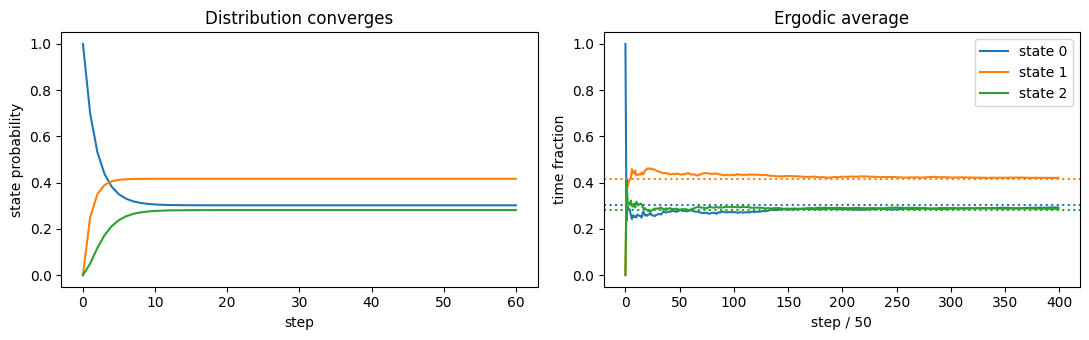

In [3]:
steps = 20_000
states = torch.empty(steps, dtype=torch.long, device=device)
states[0] = 0
for n in range(1, steps):
    states[n] = torch.multinomial(P[states[n-1]], 1)
empirical = torch.nn.functional.one_hot(states, 3).float().cumsum(0) / torch.arange(1, steps+1, device=device)[:, None]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(np.asarray(history))
ax[0].set(xlabel='step', ylabel='state probability', title='Distribution converges')
for k in range(3):
    ax[1].plot(empirical[::50, k].cpu().numpy(), label=f'state {k}')
    ax[1].axhline(float(pi[k]), color=f'C{k}', ls=':')
ax[1].set(xlabel='step / 50', ylabel='time fraction', title='Ergodic average')
ax[1].legend(); plt.tight_layout(); plt.show()